# Rede de dutos, refluxo e modelo de deriva

O severe slug como rede com vértices dinâmicos conservativos, o refluxo nas extremidades e o esquema escalonado para o modelo de deriva de Beggs & Brill.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [012](../../docs/issues/012-vf-escalonado-deriva.md)
- [013](../../docs/issues/013-filtro-anti-refluxo.md)
- [014](../../docs/issues/014-inversao-de-sentido.md)
- [025](../../docs/issues/025-vertices-conservativos.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json, warnings

warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.runs import find_run, load_run

fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05
A = np.pi * D**2 / 4
P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A


def datafile(fname):
    """Caminho de uma corrida gravada (notebooks/data ou runs/), ou None se não existir."""
    try:
        return find_run(fname)
    except FileNotFoundError:
        print("trajetória não encontrada:", fname)
        return None


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )

## Rede de dutos acoplados por vértices em vez de um duto único curvado

O mesmo caso montado como **rede**: linha (horizontal + descendente), pescoço (o
arco, como duto próprio), riser e horizontal de saída, ligados por três vértices
dinâmicos (balanço de massa num volume V, sem momento; o vértice impõe αG e P na
entrada do duto a jusante e P na saída do duto a montante). A condição inicial
bloqueada é a mesma do duto único, interpolada pelos dutos, e os vértices partem do
estado da junção. O volume do vértice é o parâmetro que não existe no duto único:
um volume grande acrescenta estoque e amortece; um volume pequeno torna o vértice
rígido (a pressão responde ao desbalanço de vazões com constante de tempo V·C).
Comparação com o duto único curvado (mesma malha, formulação conservativa, ν =
0.05, JAX, `tol_range` 0.01).

In [2]:
runs_net = {}
for tag, fname in (
    ("duto único curvado", "severe_slug_blocked_conservative_arc_tol.npz"),
    ("rede, V = 0.05 m³", "severe_slug_blocked_network_v050.npz"),
    ("rede, V = 0.005 m³", "severe_slug_blocked_network_v005.npz"),
    ("rede, V = 0.002 m³", "severe_slug_blocked_network_v002.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_net[tag] = load_blocked_run(f)

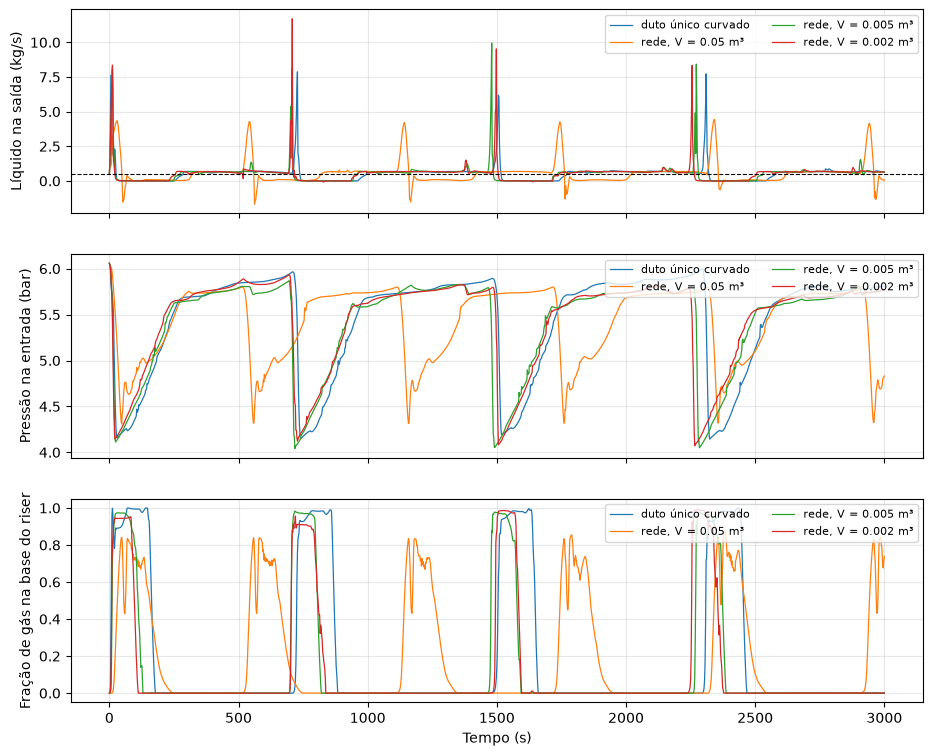

configuração           estados   passos    CPU blowdowns intervalo  pico máx   P_in (bar)
duto único curvado         112    25923    50 s         4     765 s    7.9 kg/s  4.14–6.00
rede, V = 0.05 m³          124    35518   148 s         6     582 s    4.4 kg/s  4.32–5.80
rede, V = 0.005 m³         124    61109   221 s         4     753 s   10.0 kg/s  4.04–5.87
rede, V = 0.002 m³         124    65018   225 s         4     748 s   11.7 kg/s  4.07–5.94


In [3]:
if runs_net:
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    for k, (tag, r) in enumerate(runs_net.items()):
        T_ = r["T"]
        axes[0].plot(T_, r["p_last"]["out"]["qL"][-1], lw=0.9, label=tag)
        axes[1].plot(T_, r["p"]["out"]["P_bar"][1], lw=0.9, label=tag)
        axes[2].plot(T_, r["aG_riser_base"], lw=0.9, label=tag)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8)
    axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)")
    axes[2].set_ylabel("Fração de gás na base do riser")
    axes[2].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper right", ncol=2)
    plt.show()
    print(
        f"{'configuração':22s} {'estados':>7s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s}"
    )
    for tag, r in runs_net.items():
        T_, q_ = r["T"], r["p_last"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(
            f"{tag:22s} {r['model'].n_states:7d} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f}"
        )

## Severe slug com o modelo de deriva (Beggs & Brill)?

Com o volume finito escalonado estendido ao modelo de deriva (ver o notebook do
poço 10.3.1: hold-up e pressão nas células, vazões nas faces, momento da mistura e
a relação de escorregamento imposta na forma diferenciada) o caso pode ser montado
com `severe_slug_case(model=2)`. Não é simulável com esta correlação, e o motivo é
físico: partindo da condição bloqueada (bolsão com 75 % de gás sobre líquido a
0.3 m/s, riser cheio) a restrição de escorregamento exige vazões de gás de vários
m/s para que a correlação "explique" 75 % de gás com esse líquido; aparece uma
recirculação de ±6 kg/s nas faces da entrada e o integrador para em t ≈ 2.3 s, com
derivadas exatas ou por diferenças finitas. Um bolsão parado sobre líquido em
movimento (escorregamento infinito) não é um estado de uma correlação ajustada em
escoamento co-corrente permanente. Partindo do hold-up da própria correlação
(`ic_holdup="correlation"`) a mesma geometria vai para um estado estacionário em
157 passos (P_in 4.66 bar, produção igual à alimentação, 20–30 % de gás no riser):
a correlação amarra a vazão de gás à do líquido e não há mecanismo de bloqueio do
gás pela coluna de líquido, que é o que gera o ciclo. Para ter severe slug com um
modelo de deriva seria preciso uma lei de escorregamento em velocidade
(vG = C0·vM + vd) que admita gás parado com líquido em movimento.

## Poço 10.3.1 com o escalonado de deriva (corrida `runs/issues/10_3_1_fv_drift`) contra o esquema nodal da tese
Hold-up e pressão nas células, vazões nas faces, momento da mistura da tese e a relação de escorregamento
imposta na forma diferenciada no tempo (estabilização de Baumgarte). O esquema nodal é a corrida fiel
(`runs/chapter10/10_3_1`, diferenças centrais, BDF do SciPy); o escalonado parte do seu próprio
estacionário e usa o BDF próprio.

volume finito: None passos, nan s


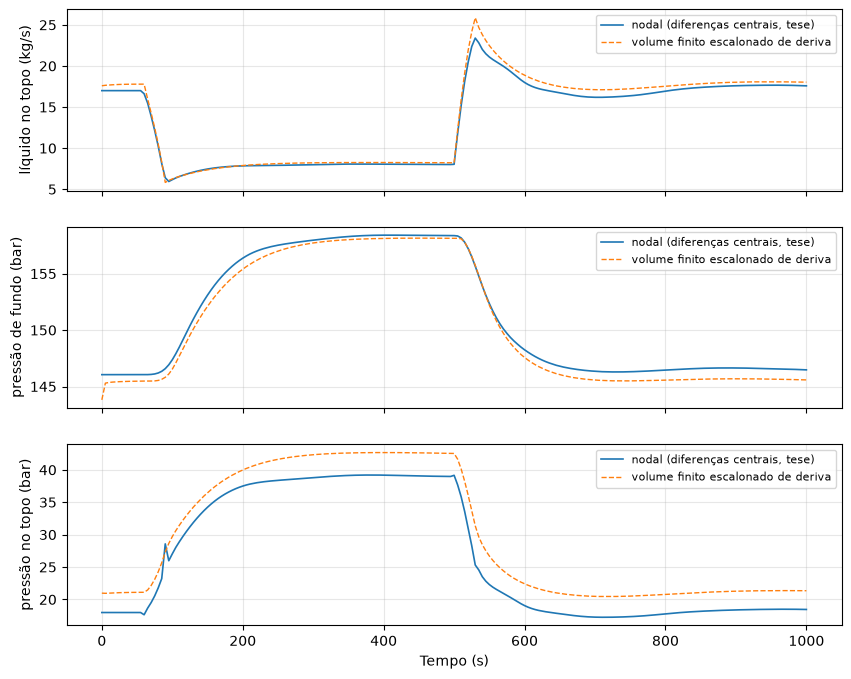

In [4]:
res_n = load_run("chapter10/10_3_1").res
res_fv = load_run("issues/10_3_1_fv_drift").res
print(f"volume finito: {res_fv.info.get('n_steps')} passos, {res_fv.info.get('cpu', float('nan')):.1f} s")
p_n, p_f = res_n.pipe(0), res_fv.pipe(0)
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for p_, res_, lab, st in (
    (p_n, res_n, "nodal (diferenças centrais, tese)", dict(lw=1.2)),
    (p_f, res_fv, "volume finito escalonado de deriva", dict(lw=1.0, ls="--")),
):
    top = -1 if p_ is p_n else -2  # no escalonado o último nó é o fantasma da válvula
    axes[0].plot(res_.T, p_["out"]["qL"][-1], label=lab, **st)
    axes[1].plot(res_.T, p_["out"]["P_bar"][0 if p_ is p_n else 1], label=lab, **st)
    axes[2].plot(res_.T, p_["out"]["P_bar"][top], label=lab, **st)
axes[0].set_ylabel("líquido no topo (kg/s)")
axes[1].set_ylabel("pressão de fundo (bar)")
axes[2].set_ylabel("pressão no topo (bar)")
axes[2].set_xlabel("Tempo (s)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.show()

As duas discretizações dão o mesmo transiente (picos de líquido na reabertura, queda de pressão de
fundo com o choke fechado); a pressão "no topo" do escalonado é a da última célula, 41 m abaixo da
válvula, por isso fica ~2 bar acima da nodal. O escalonado conserva a massa de cada fase exatamente
(acumulador consistente com o BDF; `tests/test_fv_drift.py`), o que o esquema nodal não faz.

## Refluxo
O filtro anti-refluxo do código original foi removido (013) e a fração nas extremidades por onde entra
massa passou a ser imposta pelo vértice (014); a demonstração da inversão de sentido está em
`tests/test_reversal.py` e o caso 10.2.2, que usava o filtro em quatro arestas, reproduz o MATLAB
exatamente como antes (notebook fiel `thesis/nb_10_2_2`).